## Entrega 2 -- Isabel Johana Hoyos Echavarría

## 2.5: Comparación experimental entre Merge Sort e Insertion Sort

- implementar Merge Sort,
- implementar Insertion Sort,
- medir tiempos para n = 10, 50, 100, 500, 1000, 5000,
- y hacer una gráfica comparativa.

In [1]:
import random
import time
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
def merge(left,right):
    result = [] 
    i = 0
    j = 0

    while i < len(left) and j < len(right):
        if left[i] < right[j]:
            result.append(left[i])
            i = i + 1
        else:
            result.append(right[j])
            j = j + 1
            
    result.extend(left[i:])
    result.extend(right[j:])
    return result

In [3]:
def merge_sort(arr):
    # caso base
    if len(arr) <= 1: # si el arreglo tiene un elemento o esta vacio, ya esta ordenado
        return arr # si el arreglo tiene un elemento o esta vacio, ya esta ordenado

    # Dividir
    mid = len(arr) // 2 # encontrar el punto medio del arreglo
    left = merge_sort(arr[:mid]) # ordenar la mitad izquierda del arreglo
    right = merge_sort(arr[mid:]) # ordenar la mitad derecha del arreglo

    # Combinar
    return merge(left, right) # combinar las dos mitades ordenadas

In [4]:
def insertion_sort(arr):
    resultado = arr.copy()

    for i in range(1, len(resultado)):
        key = resultado[i]
        j = i - 1
        while j >= 0 and resultado[j] > key:
            resultado[j + 1] = resultado[j]
            j = j - 1
        resultado[j + 1] = key
    return resultado

In [5]:
def medir_tiempo_ordenamiento(n):
    arr = [random.randint(0, 10000) for _ in range(n)]
    arr1 = arr.copy()

    inicio_t1 = time.time() # medir el tiempo de inicio para merge sort
    resultado_merge = merge_sort(arr) # ordenar el arreglo con merge sort
    fin_t1 = time.time() # medir el tiempo de fin para merge sort

    inicio_t2 = time.time() # medir el tiempo de inicio para insertion sort
    resultado_insertion = insertion_sort(arr1) # ordenar el arreglo con insertion sort
    fin_t2 = time.time() # medir el tiempo de fin para insertion sort

    print(f"n = {n}")
    print(f"Tiempo Merge Sort: {fin_t1 - inicio_t1:.6f} segundos")
    print(f"Tiempo Insertion Sort: {fin_t2 - inicio_t2:.6f} segundos")
    print(f"Primeros elementos merge sort: {resultado_merge[:10]}")
    print(f"Primeros elementos insertion sort: {resultado_insertion[:10]}")
    print("-" * 50)

    return fin_t1 - inicio_t1, fin_t2 - inicio_t2

n = 10
Tiempo Merge Sort: 0.000000 segundos
Tiempo Insertion Sort: 0.000000 segundos
Primeros elementos merge sort: [962, 2431, 2707, 3545, 4251, 6584, 7569, 9305, 9385, 9680]
Primeros elementos insertion sort: [962, 2431, 2707, 3545, 4251, 6584, 7569, 9305, 9385, 9680]
--------------------------------------------------
n = 50
Tiempo Merge Sort: 0.000000 segundos
Tiempo Insertion Sort: 0.000000 segundos
Primeros elementos merge sort: [157, 778, 1530, 1756, 1791, 2134, 2328, 2400, 2411, 2424]
Primeros elementos insertion sort: [157, 778, 1530, 1756, 1791, 2134, 2328, 2400, 2411, 2424]
--------------------------------------------------
n = 100
Tiempo Merge Sort: 0.000000 segundos
Tiempo Insertion Sort: 0.000000 segundos
Primeros elementos merge sort: [134, 201, 312, 433, 446, 542, 916, 1184, 1208, 1250]
Primeros elementos insertion sort: [134, 201, 312, 433, 446, 542, 916, 1184, 1208, 1250]
--------------------------------------------------
n = 500
Tiempo Merge Sort: 0.001003 segundos
Ti

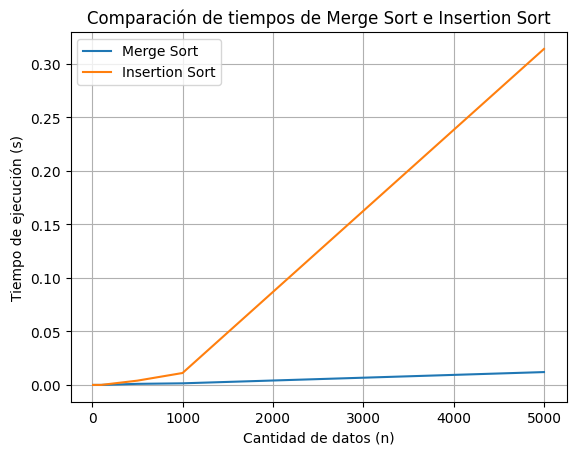

In [6]:
if __name__ == "__main__":
    tiempos_merge = []
    tiempos_insertion = []

    datos = [10, 50, 100, 500, 1000, 5000]

    for n in datos:
        tiempo_merge, tiempo_insertion = medir_tiempo_ordenamiento(n)
        tiempos_merge.append(tiempo_merge)
        tiempos_insertion.append(tiempo_insertion)

    sns.lineplot(x=datos, y=tiempos_merge, label='Merge Sort')
    sns.lineplot(x=datos, y=tiempos_insertion, label='Insertion Sort')

    plt.xlabel('Cantidad de datos (n)')
    plt.ylabel('Tiempo de ejecución (s)')
    plt.title('Comparación de tiempos de Merge Sort e Insertion Sort')
    plt.grid()
    plt.show()